# Quickstart: the adaptive cut of a dendrogram

Hierarchical clustering usually ends with one horizontal cut of the dendrogram, so every
cluster is taken at the same height. The adaptive cut cuts each branch at its own height. It
searches, with a Markov chain Monte Carlo sampler and simulated annealing, for the cut that
maximises an objective summed over clusters.

This notebook needs `pip install adaptive_cut scikit-learn matplotlib`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster.hierarchy import linkage
from sklearn.metrics import adjusted_rand_score as ari

import adaptive_cut as ac

## Data: clusters at two scales

Three tight blobs next to two wide ones. No single height of the tree separates the tight blobs
without also cutting the wide ones into pieces.

In [2]:
def blobs(seed=0):
    """Three tight blobs (150 points each) next to two wide ones (300 each)."""
    rng = np.random.default_rng(seed)
    centers = np.array([[0, 0], [1.2, 0], [0.6, 1.0], [8, 0], [4, 7]])
    std = np.array([0.25, 0.25, 0.25, 1.6, 1.6])
    y = np.repeat(np.arange(5), [150, 150, 150, 300, 300])
    X = centers[y] + std[y, None] * rng.standard_normal((len(y), 2))
    return X, y


X, y = blobs(seed=0)
X.shape

(1050, 2)

## Tree, scores and cuts

1. Build any scipy linkage matrix `Z`.
2. Give every node of the tree a score. `ac.gaussian_scores` scores a cluster by the BIC of one
   Gaussian fitted to its points, so the sum over a cut is the BIC of a Gaussian mixture with
   one component per cluster.
3. Compare the best single-level cut with the adaptive cut.

In [3]:
Z = linkage(X, "ward")
scores = ac.gaussian_scores(Z, X)  # one score per tree node

level = ac.best_level_cut(Z, scores)  # best horizontal cut
res = ac.adaptive_cut(Z, scores, T=160, n_steps=100_000, rng=0)
best = res.best  # best cut the sampler visited

for name, cut in [("single-level cut", level), ("adaptive cut", best)]:
    print(
        f"{name:>16}: {cut.n_clusters} clusters, BIC score {cut.value:8.1f}, ARI {ari(y, cut.labels):.2f}"
    )

single-level cut: 3 clusters, BIC score   3103.5, ARI 0.69
    adaptive cut: 5 clusters, BIC score   3225.8, ARI 0.96


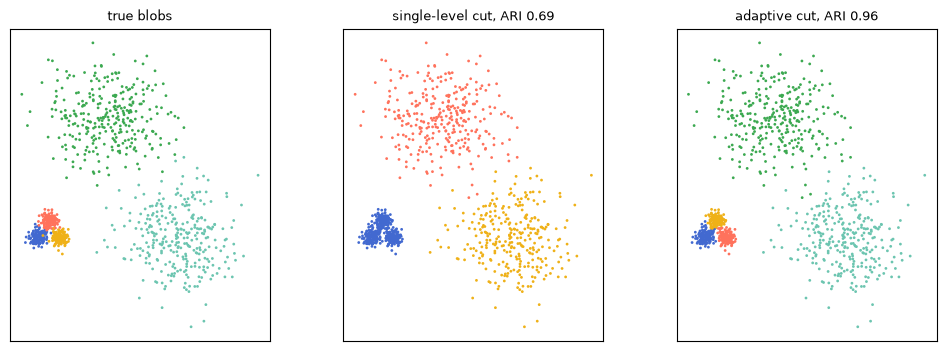

In [4]:
COLORS = np.array(
    [
        "#4269d0",
        "#efb118",
        "#ff725c",
        "#6cc5b0",
        "#3ca951",
        "#ff8ab7",
        "#a463f2",
        "#97bbf5",
        "#9c6b4e",
        "#9498a0",
    ]
)


def scatter(ax, X, labels, title):
    labels = np.asarray(labels)
    c = np.where(labels < 0, "#d0d0d0", COLORS[np.maximum(labels, 0) % len(COLORS)])
    ax.scatter(X[:, 0], X[:, 1], s=4, c=c, linewidths=0)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")


fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), layout="constrained")
scatter(axes[0], X, y, "true blobs")
scatter(axes[1], X, level.labels, f"single-level cut, ARI {ari(y, level.labels):.2f}")
scatter(axes[2], X, best.labels, f"adaptive cut, ARI {ari(y, best.labels):.2f}")

## The temperature

`T` is in units of the objective. The chain starts from the best single-level cut. To reach
the 5-cluster cut it has to pass through cuts about 30 BIC units worse. The automatic
temperature (`T="auto"`, 0.1 times the median change of the objective over single merges) is
about 2 units here, so the default chain stays where it starts. The trace of the objective
shows it.

T=auto is 1.89: 3 clusters, ARI 0.69


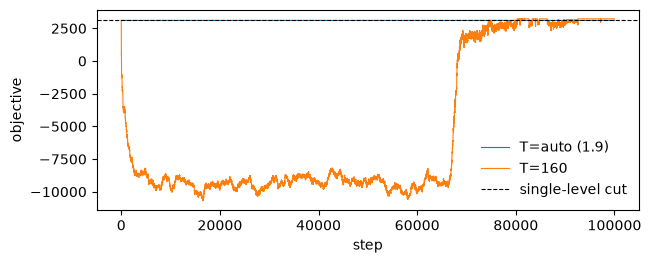

In [5]:
default = ac.adaptive_cut(Z, scores, T="auto", n_steps=100_000, rng=0)
print(f"T=auto is {default.T:.2f}: {default.n_clusters} clusters, ARI {ari(y, default.labels):.2f}")

plt.figure(figsize=(7, 2.6))
for r, name in [(default, f"T=auto ({default.T:.1f})"), (res, "T=160")]:
    plt.plot(np.arange(len(r.trace)) * r.trace_every, r.trace, lw=0.8, label=name)
plt.axhline(level.value, color="k", ls="--", lw=0.8, label="single-level cut")
plt.xlabel("step")
plt.ylabel("objective")
plt.legend(frameon=False);

If the trace stays flat at its starting value, raise `T` or `n_steps`, or start from another
cut with `init="leaves"` (all singletons) or `init="root"`.

## What the result holds

In [6]:
print(res)
print("best cut:     ", res.best)
print("last state:   ", res.final)
print("start:        ", res.initial)
print(f"gain over the start: {res.gain:.1f}, acceptance rate {res.acceptance_rate:.3f}")
print("tree nodes of the best cut:", res.best.nodes)

AdaptiveCutResult(value=3225.84, n_clusters=5, initial=3103.51, n_steps=100000, T=160, engine='numba')
best cut:      Cut(n_clusters=5, value=3225.84)
last state:    Cut(n_clusters=5, value=3225.84)
start:         Cut(n_clusters=3, value=3103.51, height=31.6511)
gain over the start: 122.3, acceptance rate 0.363
tree nodes of the best cut: [2055 2047 2051 2095 2096]
